## Experiment: comparing normal and t distributions.

Two-sided 95% critical values:
Normal: 1.9600
t, df=2: 4.3027
t, df=5: 2.5706
t, df=15: 2.1314
t, df=50: 2.0086


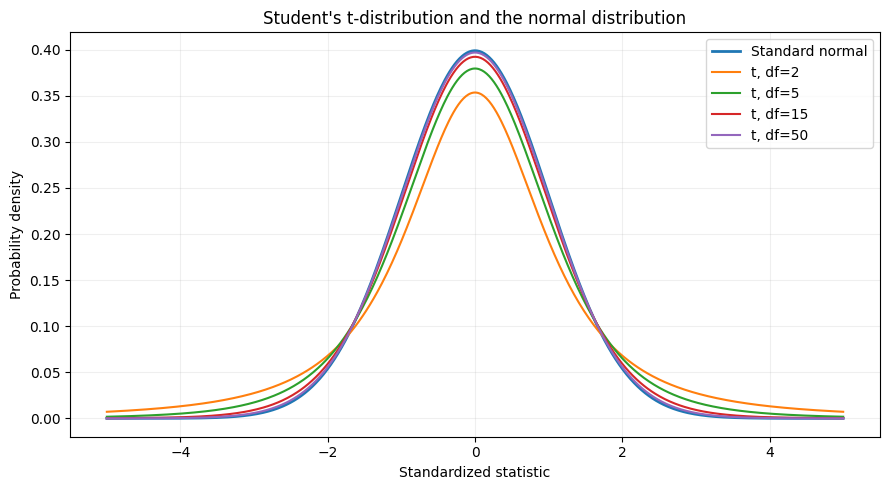

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, t

x = np.linspace(-5, 5, 600)
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(x, norm.pdf(x), linewidth=2, label="Standard normal")
for df in [2, 5, 15, 50]:
    ax.plot(x, t.pdf(x, df=df), label=f"t, df={df}")

print("Two-sided 95% critical values:")
print(f"Normal: {norm.ppf(0.975):.4f}")
for df in [2, 5, 15, 50]:
    print(f"t, df={df}: {t.ppf(0.975, df):.4f}")

ax.set_xlabel("Standardized statistic")
ax.set_ylabel("Probability density")
ax.set_title("Student's t-distribution and the normal distribution")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig("../../images/unknown_sigma_t_vs_normal.png", dpi=180, bbox_inches="tight")
plt.show()

# Experiment: compare critical values for n=5, n=20, and n=100.

## Experiment: t-test and interval from summary statistics.

In [3]:
import numpy as np
from scipy.stats import t

n, sample_mean, sample_sd = 16, 52.4, 8.0
mu_0, alpha = 50.0, 0.05

df = n - 1
se = sample_sd / np.sqrt(n)
t_observed = (sample_mean - mu_0) / se
p_two_sided = 2 * t.sf(abs(t_observed), df=df)
critical = t.ppf(1 - alpha / 2, df=df)
ci = (sample_mean - critical * se, sample_mean + critical * se)

print(f"t-statistic: {t_observed:.4f}")
print(f"Degrees of freedom: {df}")
print(f"Two-sided p-value: {p_two_sided:.4f}")
print(f"95% confidence interval: ({ci[0]:.3f}, {ci[1]:.3f})")
print("Reject H0:", p_two_sided <= alpha)

# Experiment: change the sample size while keeping the
# observed mean and standard deviation fixed.

t-statistic: 1.2000
Degrees of freedom: 15
Two-sided p-value: 0.2487
95% confidence interval: (48.137, 56.663)
Reject H0: False


## Experiment: a one-sample t-test with raw data.

In [4]:
import numpy as np
from scipy import stats

observations = np.array([
    51, 49, 54, 50, 56, 53, 48, 52, 55, 50, 54, 51
], dtype=float)
mu_0 = 50.0
alpha = 0.05

result = stats.ttest_1samp(
    observations, popmean=mu_0, alternative="two-sided"
)

n = len(observations)
mean = np.mean(observations)
s = np.std(observations, ddof=1)
se = s / np.sqrt(n)
t_critical = stats.t.ppf(1 - alpha / 2, df=n - 1)
manual_ci = (mean - t_critical * se, mean + t_critical * se)
scipy_ci = result.confidence_interval(confidence_level=0.95)

print(f"Mean: {mean:.3f}")
print(f"Sample SD: {s:.3f}")
print(f"t: {result.statistic:.4f}, p: {result.pvalue:.4f}")
print(f"Degrees of freedom: {result.df}")
print(f"Manual CI: {manual_ci}")
print(f"SciPy CI: ({scipy_ci.low:.4f}, {scipy_ci.high:.4f})")

# Experiment: try alternative="greater" and "less".
# The p-values and corresponding confidence bounds change.

Mean: 51.917
Sample SD: 2.503
t: 2.6526, p: 0.0225
Degrees of freedom: 11
Manual CI: (50.326318251131674, 53.507015082201654)
SciPy CI: (50.3263, 53.5070)


## Experiment: coverage with estimated standard deviation.

n=  5, t coverage=0.950, naive z coverage=0.880
n= 10, t coverage=0.948, naive z coverage=0.917
n= 30, t coverage=0.951, naive z coverage=0.941
n=100, t coverage=0.948, naive z coverage=0.946


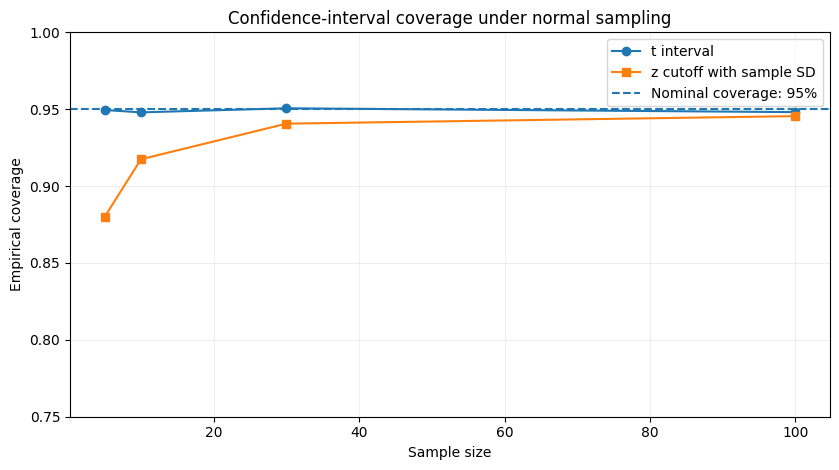

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, t

rng = np.random.default_rng(2026)
mu, sigma, alpha = 50.0, 8.0, 0.05
repetitions = 20_000
sample_sizes = [5, 10, 30, 100]

t_coverages = []
naive_z_coverages = []

for n in sample_sizes:
    samples = rng.normal(mu, sigma, size=(repetitions, n))
    means = samples.mean(axis=1)
    estimated_se = samples.std(axis=1, ddof=1) / np.sqrt(n)

    t_margin = t.ppf(1 - alpha / 2, df=n - 1) * estimated_se
    z_margin = norm.ppf(1 - alpha / 2) * estimated_se

    t_covered = np.mean(np.abs(means - mu) <= t_margin)
    z_covered = np.mean(np.abs(means - mu) <= z_margin)
    t_coverages.append(t_covered)
    naive_z_coverages.append(z_covered)
    print(f"n={n:3d}, t coverage={t_covered:.3f}, "
          f"naive z coverage={z_covered:.3f}")

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.plot(sample_sizes, t_coverages, marker="o", label="t interval")
ax.plot(sample_sizes, naive_z_coverages, marker="s",
        label="z cutoff with sample SD")
ax.axhline(0.95, linestyle="--", label="Nominal coverage: 95%")
ax.set_xlabel("Sample size")
ax.set_ylabel("Empirical coverage")
ax.set_title("Confidence-interval coverage under normal sampling")
ax.set_ylim(0.75, 1.00)
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig("../../images/unknown_sigma_ci_coverage.png", dpi=180, bbox_inches="tight")
plt.show()

# Experiment: repeat using a skewed population.

## Experiment: t-intervals for a skewed population.

n=  5: 95% t-interval coverage = 0.878
n= 10: 95% t-interval coverage = 0.897
n= 30: 95% t-interval coverage = 0.924
n=100: 95% t-interval coverage = 0.940
n=300: 95% t-interval coverage = 0.947


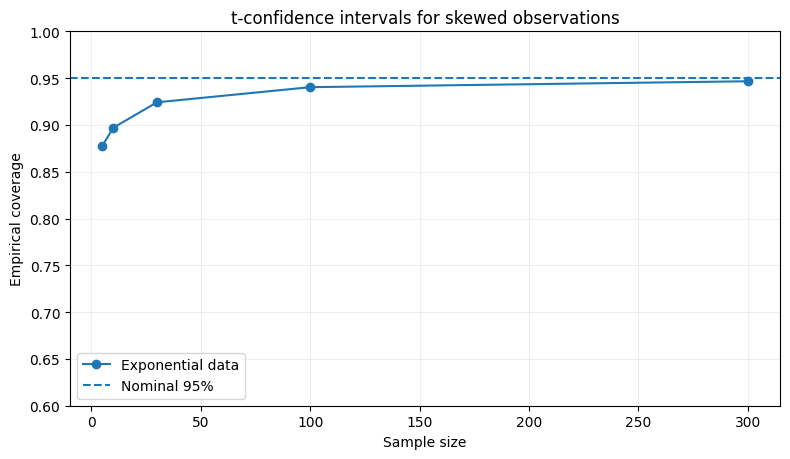

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t

rng = np.random.default_rng(2026)
true_mean = 1.0
repetitions = 12_000
sample_sizes = [5, 10, 30, 100, 300]

coverages = []
for n in sample_sizes:
    samples = rng.exponential(scale=1.0, size=(repetitions, n))
    means = samples.mean(axis=1)
    ses = samples.std(axis=1, ddof=1) / np.sqrt(n)
    margin = t.ppf(0.975, df=n - 1) * ses
    coverage = np.mean(np.abs(means - true_mean) <= margin)
    coverages.append(coverage)
    print(f"n={n:3d}: 95% t-interval coverage = {coverage:.3f}")

fig, ax = plt.subplots(figsize=(8, 4.7))
ax.plot(sample_sizes, coverages, marker="o", label="Exponential data")
ax.axhline(0.95, linestyle="--", label="Nominal 95%")
ax.set_xlabel("Sample size")
ax.set_ylabel("Empirical coverage")
ax.set_title("t-confidence intervals for skewed observations")
ax.set_ylim(0.6, 1.0)
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig("../../images/unknown_sigma_skew_coverage.png", dpi=180, bbox_inches="tight")
plt.show()

# Experiment: replace the exponential distribution by normal data.

## Experiment: power and sample-size planning.

Power at n=25: 0.6697
Minimum n for at least 80% power: 34


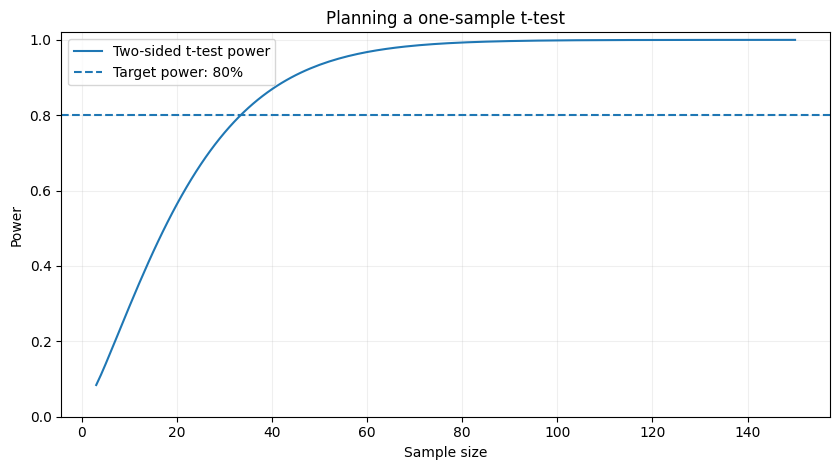

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import nct, t

alpha = 0.05
sigma = 10.0
mu_0 = 100.0
mu_1 = 105.0


def two_sided_t_power(n, mean_difference, sigma, alpha=0.05):
    df = n - 1
    delta = np.sqrt(n) * mean_difference / sigma
    critical = t.ppf(1 - alpha / 2, df=df)
    return nct.cdf(-critical, df=df, nc=delta) + nct.sf(
        critical, df=df, nc=delta
    )


sample_sizes = np.arange(3, 151)
powers = np.array([
    two_sided_t_power(n, mu_1 - mu_0, sigma, alpha)
    for n in sample_sizes
])

eligible = sample_sizes[powers >= 0.80]
minimum_n = int(eligible[0]) if len(eligible) else None

print(f"Power at n=25: {two_sided_t_power(25, 5, 10):.4f}")
print("Minimum n for at least 80% power:", minimum_n)

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.plot(sample_sizes, powers, label="Two-sided t-test power")
ax.axhline(0.80, linestyle="--", label="Target power: 80%")
ax.set_xlabel("Sample size")
ax.set_ylabel("Power")
ax.set_ylim(0, 1.02)
ax.set_title("Planning a one-sample t-test")
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig("../../images/unknown_sigma_t_power.png", dpi=180, bbox_inches="tight")
plt.show()

# Experiment: use a smaller effect or larger population SD.
# How does the required sample size change?

## Experiment: SOGA-Py student weights.

In [8]:
import numpy as np
import pandas as pd
from scipy import stats

url = (
    "https://userpage.fu-berlin.de/"
    "soga/data/raw-data/students.csv"
)
students = pd.read_csv(url)

sample_weights = students.sample(n=9, random_state=9)["weight"]
if sample_weights.isna().any():
    raise ValueError("The selected sample contains missing weights.")

mu_0 = 70.8
alpha = 0.05
result = stats.ttest_1samp(
    sample_weights, popmean=mu_0, alternative="two-sided"
)
ci = result.confidence_interval(confidence_level=0.95)

print("Sample size:", len(sample_weights))
print(f"Mean: {sample_weights.mean():.3f} kg")
print(f"Sample SD: {sample_weights.std(ddof=1):.3f} kg")
print(f"t-statistic: {result.statistic:.4f}")
print(f"p-value: {result.pvalue:.4f}")
print("Degrees of freedom:", result.df)
print(f"95% confidence interval: [{ci.low:.3f}, {ci.high:.3f}]")
print("Reject H0 at 5%:", result.pvalue <= alpha)

# Experiment: increase the sample size, keeping the
# benchmark and the original dataset unchanged.

Sample size: 9
Mean: 73.389 kg
Sample SD: 6.684 kg
t-statistic: 1.1620
p-value: 0.2787
Degrees of freedom: 8
95% confidence interval: [68.251, 78.527]
Reject H0 at 5%: False
